# 🛠️ Simulación de Tráfico Vehicular con HMM Avanzado (Smart City Dashboard)

**Asignatura:** Simulación de Sistemas / Modelado Estocástico  
**Tema:** Modelos Ocultos de Markov (HMM) con Matriz de Transición Dinámica e Incidentes Viales  

---  
### 📌 Descripción del Proyecto
Este notebook contiene la implementación completa de un **Modelo Oculto de Markov (HMM)** para simular y analizar el tráfico de una arteria vial urbana durante un periodo de 24 horas (48 intervalos de 30 minutos).

**Novedad / Modificación Principal Añadida:**
A diferencia del modelo estándar con probabilidades estáticas, este notebook incorpora la Simulación Dinámica de Incidentes Viales (Accidentes de Tránsito / Lluvia Intensa). Esto permite realizar un Análisis de Sensibilidad, comparando el comportamiento del tráfico en un Día Normal (Escenario Base) versus un Día con Incidente (Escenario Perturbado), evaluando el impacto en tiempos de retraso, emisiones de $CO_2$ y capacidad de detección con el Algoritmo de Viterbi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Configuración de reproducibilidad
np.random.seed(42)

print('✅ Librerías cargadas exitosamente.')

✅ Librerías cargadas exitosamente.


---
## 1. Definición de la Clase TrafficHMM con Matriz Dinámica

En esta sección definimos la estructura del HMM:
- **Estados Ocultos ($S$):** $S_0$ = Tráfico Fluido, $S_1$ = Tráfico Moderado, $S_2$ = Tráfico Congestionado.
- **Observaciones ($V$):** $V_0$ = Velocidad Alta, $V_1$ = Velocidad Media, $V_2$ = Velocidad Baja.
- **Matriz $A$ (Transición):** Determina la probabilidad de cambiar de un estado a otro.
- **Matriz $B$ (Emisión):** Determina la probabilidad de observar cierta velocidad según el estado oculto.

In [2]:
class TrafficHMM:
    def __init__(self):
        self.states = ['Tráfico Fluido', 'Tráfico Moderado', 'Tráfico Congestionado']
        self.observations = ['Velocidad Alta', 'Velocidad Media', 'Velocidad Baja']

        # Distribución de probabilidad inicial (pi)
        self.pi = np.array([0.5, 0.3, 0.2])

        # Matriz de Transición Estándar (A_base)
        self.A_base = np.array([
            [0.70, 0.25, 0.05],  # Fluido -> [Fluido, Moderado, Congestionado]
            [0.30, 0.50, 0.20],  # Moderado
            [0.10, 0.40, 0.50]   # Congestionado
        ])

        # Matriz de Transición Perturbada / Incidente (A_incidente)
        # Alta probabilidad de caer y mantenerse en colapso vial
        self.A_incidente = np.array([
            [0.20, 0.50, 0.30],  # Fluido pasa rápidamente a moderado/congestionado
            [0.05, 0.35, 0.60],  # Moderado migra masivamente a congestionado
            [0.02, 0.18, 0.80]   # Congestionado se vuelve persistente (embotellamiento)
        ])

        # Matriz de Emisión (B)
        self.B = np.array([
            [0.80, 0.15, 0.05],  # Fluido -> [Alta, Media, Baja]
            [0.20, 0.60, 0.20],  # Moderado
            [0.05, 0.25, 0.70]   # Congestionado
        ])

    def simulate(self, n_steps=48, incidente_start=None, incidente_end=None):
        """Simula estados y observaciones, permitiendo una ventana de incidente vial"""
        state_sequence = []
        obs_sequence = []

        # Paso inicial t = 0
        current_state_idx = np.random.choice(len(self.states), p=self.pi)
        state_sequence.append(current_state_idx)
        current_obs_idx = np.random.choice(len(self.observations), p=self.B[current_state_idx])
        obs_sequence.append(current_obs_idx)

        # Pasos subsecuentes t > 0
        for step in range(1, n_steps):
            # Selección dinámica de la matriz de transición
            if incidente_start is not None and incidente_end is not None and (incidente_start <= step <= incidente_end):
                A_current = self.A_incidente
            else:
                A_current = self.A_base

            # Transición de estado
            current_state_idx = np.random.choice(len(self.states), p=A_current[current_state_idx])
            state_sequence.append(current_state_idx)

            # Emisión de observación
            current_obs_idx = np.random.choice(len(self.observations), p=self.B[current_state_idx])
            obs_sequence.append(current_obs_idx)

        return np.array(state_sequence), np.array(obs_sequence)

    def viterbi(self, obs_seq):
        """Algoritmo de Viterbi para decodificar la secuencia óptima de estados ocultos"""
        N = len(self.states)
        T = len(obs_seq)
        viterbi_table = np.zeros((N, T))
        backpointer = np.zeros((N, T), dtype=int)

        for s in range(N):
            viterbi_table[s, 0] = self.pi[s] * self.B[s, obs_seq[0]]
            backpointer[s, 0] = 0

        for t in range(1, T):
            for s in range(N):
                prob = viterbi_table[:, t-1] * self.A_base[:, s] * self.B[s, obs_seq[t]]
                viterbi_table[s, t] = np.max(prob)
                backpointer[s, t] = np.argmax(prob)

        best_path = np.zeros(T, dtype=int)
        best_path[-1] = np.argmax(viterbi_table[:, -1])
        for t in range(T-2, -1, -1):
            best_path[t] = backpointer[best_path[t+1], t+1]

        return best_path

print('✅ Clase TrafficHMM configurada correctamente.')

✅ Clase TrafficHMM configurada correctamente.


---
## 2. Generación de Datos: Escenario Base vs. Escenario con Incidente Vial

Generamos dos corridas de simulación:
1. **Escenario Base (Día Normal):** Tráfico regular sin eventos estocásticos perturbadores.
2. **Escenario Incidente (Accidente a las 08:00 AM):** Se simula un choque múltiple o lluvia torrencial entre las 08:00 AM y las 11:00 AM (intervalos 16 al 22).

In [3]:
hmm = TrafficHMM()

# Simulación 1: Día Normal
np.random.seed(42)
states_base, obs_base = hmm.simulate(n_steps=48)

# Simulación 2: Día con Incidente entre 08:00 AM (paso 16) y 11:00 AM (paso 22)
np.random.seed(42)  # Misma semilla para comparar impacto directo del incidente
states_inc, obs_inc = hmm.simulate(n_steps=48, incidente_start=16, incidente_end=22)

# Decodificación Viterbi
viterbi_base = hmm.viterbi(obs_base)
viterbi_inc = hmm.viterbi(obs_inc)

# Crear lista de horarios (24 horas, pasos de 30 min)
start_time = datetime.strptime("00:00", "%H:%M")
time_labels = [(start_time + timedelta(minutes=30 * i)).strftime("%H:%M") for i in range(48)]

# Mapeo a velocidades continuas (km/h)
def generador_velocidades(obs_seq):
    speeds = []
    for obs in obs_seq:
        if obs == 0:    # Alta
            speeds.append(np.random.uniform(80, 100))
        elif obs == 1:  # Media
            speeds.append(np.random.uniform(40, 80))
        else:          # Baja
            speeds.append(np.random.uniform(5, 40))
    return speeds

np.random.seed(101)
speeds_base = generador_velocidades(obs_base)
np.random.seed(101)
speeds_inc = generador_velocidades(obs_inc)

# Consolidar DataFrames
df_sim = pd.DataFrame({
    'Hora': time_labels,
    'Estado_Base': [hmm.states[s] for s in states_base],
    'Velocidad_Base': speeds_base,
    'Estado_Incidente': [hmm.states[s] for s in states_inc],
    'Velocidad_Incidente': speeds_inc,
    'Viterbi_Detectado_Inc': [hmm.states[s] for s in viterbi_inc]
})

# Mostrar muestra comparativa durante el horario del incidente (08:00 a 11:00 AM)
display(df_sim.iloc[15:24])

,Hora,Estado_Base,Velocidad_Base,Estado_Incidente,Velocidad_Incidente,Viterbi_Detectado_Inc
15,07:30,Tráfico Fluido,84.647073,Tráfico Fluido,84.647073,Tráfico Fluido
16,08:00,Tráfico Fluido,43.342457,Tráfico Fluido,43.342457,Tráfico Moderado
17,08:30,Tráfico Congestionado,26.124195,Tráfico Congestionado,26.124195,Tráfico Congestionado
18,09:00,Tráfico Moderado,94.579855,Tráfico Congestionado,69.159710,Tráfico Congestionado
19,09:30,Tráfico Moderado,51.049553,Tráfico Congestionado,14.668359,Tráfico Congestionado
20,10:00,Tráfico Fluido,93.706127,Tráfico Moderado,67.412253,Tráfico Moderado
21,10:30,Tráfico Fluido,60.714699,Tráfico Fluido,60.714699,Tráfico Moderado
22,11:00,Tráfico Fluido,80.969691,Tráfico Moderado,41.939381,Tráfico Moderado
23,11:30,Tráfico Fluido,82.757385,Tráfico Moderado,45.514770,Tráfico Moderado


---
## 3. Reporte de Métricas y Análisis Ambiental Comparativo

Calculamos el **Índice de Congestión**, **Horas de Retraso Acumuladas** y la **Huella Ecológica ($CO_2$)** para medir numéricamente el impacto del incidente vial.

In [4]:
print("===========================================================")
print("📊 REPORTE DE ANÁLISIS DE SENSIBILIDAD E IMPACTO DE INCIDENTES")
print("===========================================================\n")

# Factores de emisión CO2 (g/km)
factors_co2 = {'Tráfico Fluido': 150, 'Tráfico Moderado': 210, 'Tráfico Congestionado': 350}
df_sim['CO2_Base'] = df_sim['Estado_Base'].map(factors_co2)
df_sim['CO2_Incidente'] = df_sim['Estado_Incidente'].map(factors_co2)

# Horas de congestión extrema
horas_cong_base = (df_sim['Estado_Base'] == 'Tráfico Congestionado').sum() * 0.5
horas_cong_inc = (df_sim['Estado_Incidente'] == 'Tráfico Congestionado').sum() * 0.5

# Velocidad media global
vel_media_base = df_sim['Velocidad_Base'].mean()
vel_media_inc = df_sim['Velocidad_Incidente'].mean()

# Emisión total promedio CO2
co2_mean_base = df_sim['CO2_Base'].mean()
co2_mean_inc = df_sim['CO2_Incidente'].mean()

print(f"1️⃣ TIEMPO EN CONGESTIÓN EXTREMA:")
print(f"   - Escenario Base: {horas_cong_base:.1f} horas")
print(f"   - Escenario con Incidente: {horas_cong_inc:.1f} horas (Incremento: +{horas_cong_inc - horas_cong_base:.1f} hrs)")

print(f"\n2️⃣ VELOCIDAD PROMEDIO RED VIAL:")
print(f"   - Escenario Base: {vel_media_base:.2f} km/h")
print(f"   - Escenario con Incidente: {vel_media_inc:.2f} km/h (Caída: {vel_media_base - vel_media_inc:.2f} km/h)")

print(f"\n3️⃣ IMPACTO AMBIENTAL (EMISIONES CO2):")
print(f"   - Emisión Promedio Base: {co2_mean_base:.1f} g CO2/km")
print(f"   - Emisión Promedio con Incidente: {co2_mean_inc:.1f} g CO2/km")
print(f"   - Incremento relativo por colapso vial: +{((co2_mean_inc - co2_mean_base)/co2_mean_base)*100:.2f}%")

📊 REPORTE DE ANÁLISIS DE SENSIBILIDAD E IMPACTO DE INCIDENTES

1️⃣ TIEMPO EN CONGESTIÓN EXTREMA:
   - Escenario Base: 3.0 horas
   - Escenario con Incidente: 4.0 horas (Incremento: +1.0 hrs)

2️⃣ VELOCIDAD PROMEDIO RED VIAL:
   - Escenario Base: 68.46 km/h
   - Escenario con Incidente: 65.04 km/h (Caída: 3.42 km/h)

3️⃣ IMPACTO AMBIENTAL (EMISIONES CO2):
   - Emisión Promedio Base: 193.8 g CO2/km
   - Emisión Promedio con Incidente: 204.6 g CO2/km
   - Incremento relativo por colapso vial: +5.59%


---
## 4. Visualizaciones Comparativas (Smart City Dashboard Avanzado)

Graficamos la evolución del tráfico comparando el Día Normal vs. Día con Incidente Vial para evidenciar el colapso operativo de la vía.

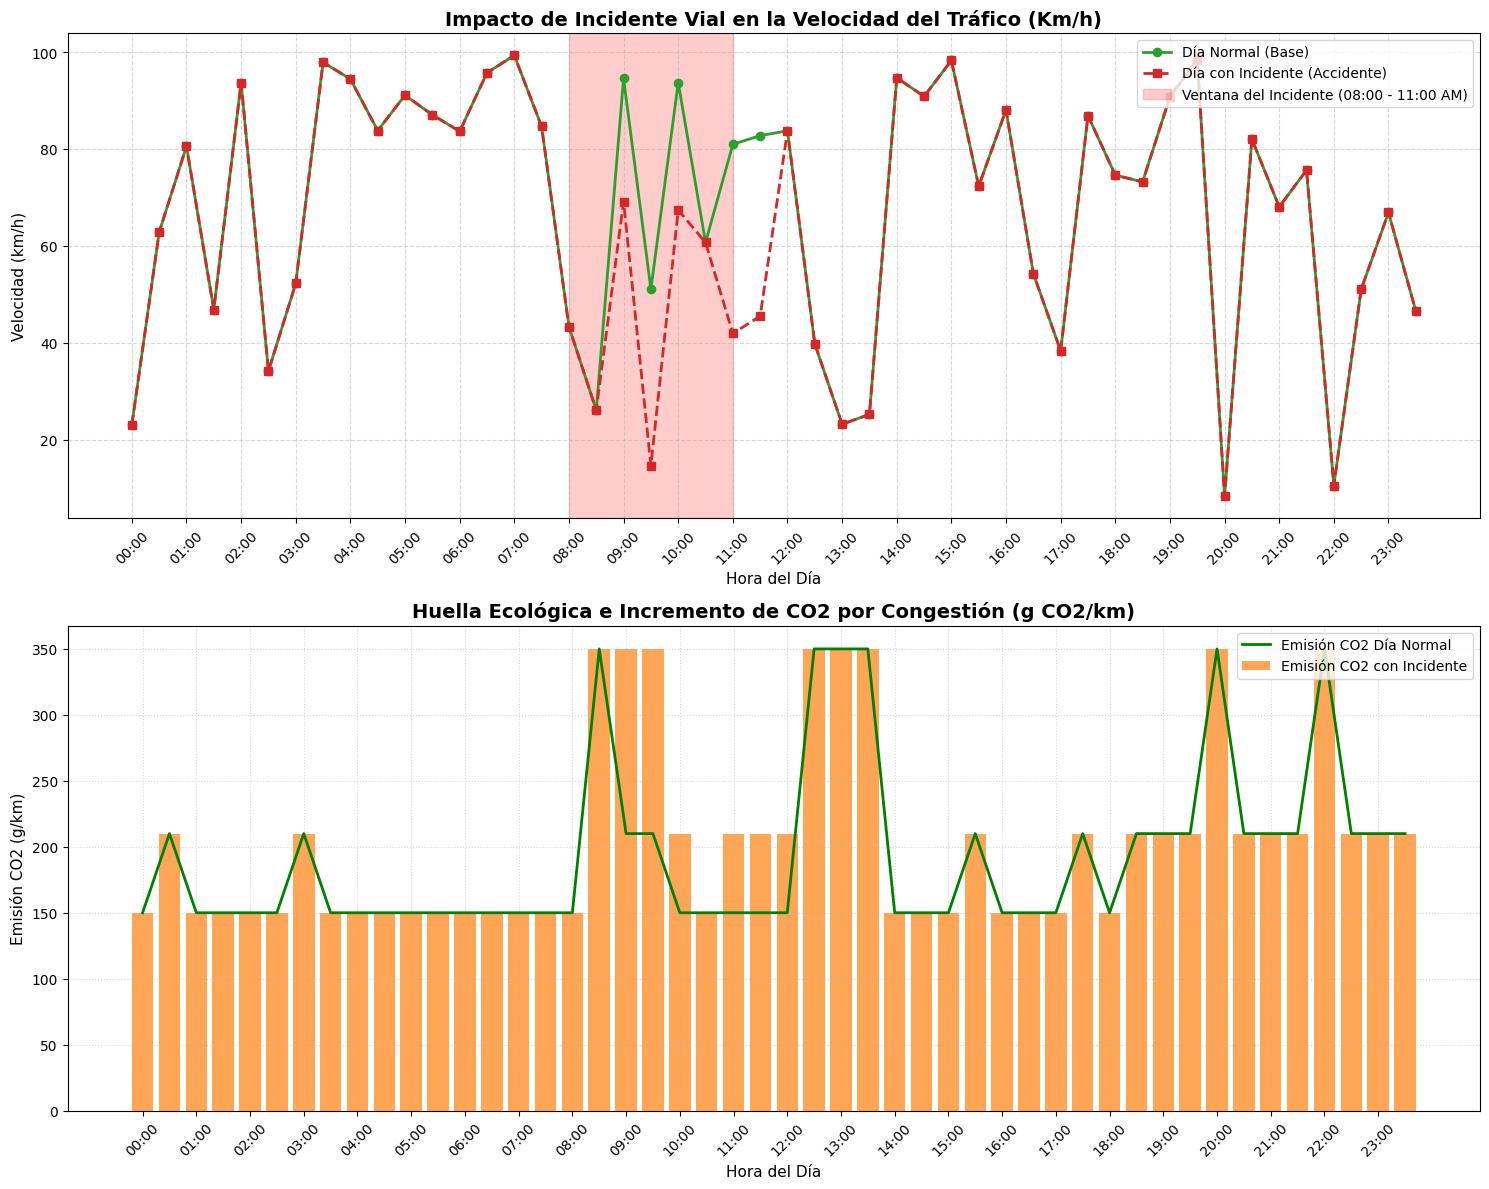

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(15, 12))

# Subplot 1: Comparativa de Velocidades Continuas
axs[0].plot(df_sim['Hora'], df_sim['Velocidad_Base'], marker='o', label='Día Normal (Base)', color='#2ca02c', linewidth=2)
axs[0].plot(df_sim['Hora'], df_sim['Velocidad_Incidente'], marker='s', label='Día con Incidente (Accidente)', color='#d62728', linewidth=2, linestyle='--')
axs[0].axvspan(16, 22, color='red', alpha=0.2, label='Ventana del Incidente (08:00 - 11:00 AM)')
axs[0].set_title('Impacto de Incidente Vial en la Velocidad del Tráfico (Km/h)', fontsize=14, fontweight='bold')
axs[0].set_xlabel('Hora del Día', fontsize=11)
axs[0].set_ylabel('Velocidad (km/h)', fontsize=11)
axs[0].set_xticks(range(0, 48, 2))
axs[0].set_xticklabels(time_labels[::2], rotation=45)
axs[0].grid(True, linestyle='--', alpha=0.5)
axs[0].legend(loc='upper right')

# Subplot 2: Comparativa de Emisiones de CO2
axs[1].bar(df_sim['Hora'], df_sim['CO2_Incidente'], color='#ff7f0e', alpha=0.7, label='Emisión CO2 con Incidente')
axs[1].plot(df_sim['Hora'], df_sim['CO2_Base'], color='green', linewidth=2, label='Emisión CO2 Día Normal')
axs[1].set_title('Huella Ecológica e Incremento de CO2 por Congestión (g CO2/km)', fontsize=14, fontweight='bold')
axs[1].set_xlabel('Hora del Día', fontsize=11)
axs[1].set_ylabel('Emisión CO2 (g/km)', fontsize=11)
axs[1].set_xticks(range(0, 48, 2))
axs[1].set_xticklabels(time_labels[::2], rotation=45)
axs[1].grid(True, linestyle=':', alpha=0.5)
axs[1].legend(loc='upper right')

plt.tight_layout()
plt.show()